In [3]:
!pip install matminer

In [4]:
from matminer.datasets import load_dataset

df = load_dataset("matbench_expt_gap") #논문들에서 모은 무기 고체(inorganic solids)의 실험 밴드갭
print(df.shape)
df.head()

(4604, 2)


,composition,gap expt
0,Ag(AuS)2,0.00
1,Ag(W3Br7)2,0.00
2,Ag0.5Ge1Pb1.75S4,1.83
3,Ag0.5Ge1Pb1.75Se4,1.51
4,Ag2BBr,0.00



*   load_dataset("matbench_expt_gap"): 인터넷에서 실험 밴드갭 데이터셋을 내려받아요. 처음 한 번은 조금 걸려요.


* df: 데이터프레임(DataFrame)의 줄임말이에요. 엑셀 표라고 생각하면 돼요.


* df.shape: 표의 크기를 (행 수, 열 수)로 알려줘요.


* df.head(): 표의 맨 위 5줄만 보여줘요.

In [5]:
from matminer.datasets import get_all_dataset_info  #밴드갭 레퍼런스 찾기
print(get_all_dataset_info("matbench_expt_gap"))

Dataset: matbench_expt_gap
Description: Matbench v0.1 test dataset for predicting experimental band gap from composition alone. Retrieved from Zhuo et al. supplementary information. Deduplicated according to composition, removing compositions with reported band gaps spanning more than a 0.1eV range; remaining compositions were assigned values based on the closest experimental value to the mean experimental value for that composition among all reports. For benchmarking w/ nested cross validation, the order of the dataset must be identical to the retrieved data; refer to the Automatminer/Matbench publication for more details.
Columns:
	composition: Chemical formula.
	gap expt: Target variable. Experimentally measured gap, in eV.
Num Entries: 4604
Reference: Y. Zhuo, A. Masouri Tehrani, J. Brgoch (2018) Predicting the Band Gaps of Inorganic Solids by Machine Learning J. Phys. Chem. Lett. 2018, 9, 7, 1668-1673 https:doi.org/10.1021/acs.jpclett.8b00124.
Bibtex citations: ["@Article{Dunn2020

In [6]:
print(df["gap expt"].describe())
print("밴드갭이 0인 물질 수:", (df["gap expt"] == 0).sum())  #밴드갭이 0 인 물질 = 금속
print("금속의 비율:", ((df["gap expt"]==0).sum()/len(df))*100)

count    4604.000000
mean        0.975951
std         1.445034
min         0.000000
25%         0.000000
50%         0.000000
75%         1.812500
max        11.700000
Name: gap expt, dtype: float64
밴드갭이 0인 물질 수: 2450
금속의 비율: 53.214596003475236


* df["gap expt"]: 밴드갭 열만 꺼내요.

* .describe(): 개수, 평균(mean), 표준편차(std), 최소(min), 최대(max), 사분위수를 한 번에 보여줘요.

* (df["gap expt"] == 0).sum(): 값이 0인 행이 몇 개인지 세요. 조건에 맞으면 True(1), 아니면 False(0)로 바꿔서 더하는 원리예요.

> 밴드갭이 아주 큰 물질은 보통 전기음성도 차이가 큰 원소끼리 이온결합한 화합물이에요. \
대표적으로 플루오린(F) 화합물 같은 거요. 전자가 음이온에 꽉 붙잡혀서 떼어내기가 매우 어렵거든요.

In [7]:
#실제 어떤 화합물인지 보자
df.loc[df["gap expt"].idxmax()]

,2437
composition,LiF
gap expt,11.7


In [8]:
#컴퓨터는 “LiF”라는 글자를 이해 못 해요. 그래서 화학식을 숫자 목록으로 바꿔야 해요.

from matminer.featurizers.conversions import StrToComposition

df = StrToComposition(target_col_id="comp_obj").featurize_dataframe(df, "composition")
df.head()

StrToComposition:   0%|          | 0/4604 [00:00<?, ?it/s]

,composition,gap expt,comp_obj
0,Ag(AuS)2,0.00,"(Ag, Au, S)"
1,Ag(W3Br7)2,0.00,"(Ag, W, Br)"
2,Ag0.5Ge1Pb1.75S4,1.83,"(Ag, Ge, Pb, S)"
3,Ag0.5Ge1Pb1.75Se4,1.51,"(Ag, Ge, Pb, Se)"
4,Ag2BBr,0.00,"(Ag, B, Br)"


In [9]:
#각 원소의 물성(전기음성도, 원자 반지름, 녹는점 등)을 가져와서 화합물 전체의 통계값으로 만들기

from matminer.featurizers.composition import ElementProperty

ep = ElementProperty.from_preset("magpie")
df = ep.featurize_dataframe(df, col_id="comp_obj", ignore_errors=True)
print(df.shape)

ElementProperty:   0%|          | 0/4604 [00:00<?, ?it/s]

(4604, 135)


`X (입력, 특징)`: 모델이 보고 판단하는 정보, 즉 숫자 132개예요.


`y (정답, 타깃)`: 맞혀야 하는 값, 즉 밴드갭이에요.

In [10]:
feature_cols = ep.feature_labels()

print("빈 값이 있는 행 수:", df[feature_cols].isna().any(axis=1).sum())

df = df.dropna(subset=feature_cols)
X = df[feature_cols].values
y = df["gap expt"].values
print(X.shape, y.shape)

빈 값이 있는 행 수: 0
(4604, 132) (4604,)


In [11]:
#4단계-1: 기준선(baseline) 먼저 재기
#아까 말한 함정을 숫자로 확인해 볼게요. "아무 생각 없이 찍으면 점수가 얼마나 나오나?"부터 봐요.

import numpy as np
from sklearn.metrics import mean_absolute_error

pred_zero = np.zeros_like(y)
pred_mean = np.full_like(y, y.mean())

#MAE(평균절대오차, Mean Absolute Error): 예측과 정답의 차이를 절댓값으로 평균. 단위는 eV이고, 작을수록 좋아요.
print("전부 0으로 찍기  MAE:", mean_absolute_error(y, pred_zero))
print("평균 밴드갭:", y.mean())
print("전부 평균으로 찍기 MAE:", mean_absolute_error(y, pred_mean))

전부 0으로 찍기  MAE: 0.9759513466550827
평균 밴드갭: 0.9759513466550827
전부 평균으로 찍기 MAE: 1.1432002429044061


오차를 제곱해서 평균 내는 지표(MSE)를 쓰면 반대로 평균이 최적

어떤 지표를 쓰느냐에 따라 "좋은 찍기"가 달라진다는 점이 핵심

In [12]:
#4단계-2: 랜덤 포레스트 학습

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict

model = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0)
cv = KFold(n_splits=5, shuffle=True, random_state=0)
y_pred = cross_val_predict(model, X, y, cv=cv)

print("모델 MAE:", mean_absolute_error(y, y_pred))

모델 MAE: 0.44600124319087614


* 랜덤 포레스트(Random Forest): "이 특징이 몇보다 크면 오른쪽, 아니면 왼쪽" 하고 갈라지는 결정 나무(decision tree)를 300그루(n_estimators=300) 만들어서, 그 예측을 평균 내는 모델이에요.

* 5-fold 교차검증(cross-validation): 데이터를 5조각으로 나눠요. 4조각으로 공부하고 나머지 1조각으로 시험 보는 걸 5번 반복해요. 그러면 모든 물질이 한 번씩, 모델이 본 적 없는 상태에서 예측돼요.
* random_state=0: 랜덤 요소를 고정해서 실행할 때마다 같은 결과가 나오게 해요.

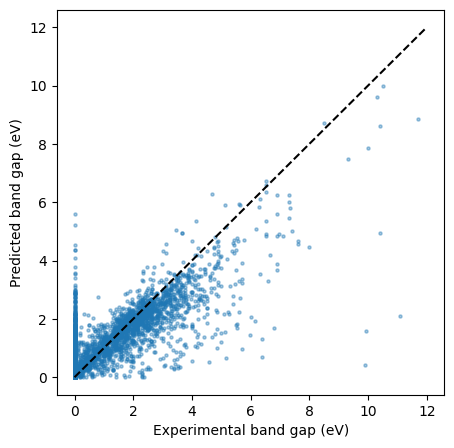

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.scatter(y, y_pred, s=5, alpha=0.4)
plt.plot([0, 12], [0, 12], "k--")
plt.xlabel("Experimental band gap (eV)")
plt.ylabel("Predicted band gap (eV)")
plt.savefig("parity.png", dpi=200)
plt.show()

연구자가 쓰는 표현 그대로예요. 이 패턴을 "평균 쪽으로 끌려가는(regression toward the mean)" 현상이라고 해요. 작은 값은 높게, 큰 값은 낮게 예측되는 거예요.



In [14]:
import pandas as pd

model.fit(X, y)
imp = pd.Series(model.feature_importances_, index=feature_cols)
print(imp.sort_values(ascending=False).head(10))

MagpieData mean NpValence               0.224211
MagpieData range NdValence              0.042955
MagpieData minimum GSvolume_pa          0.038621
MagpieData mean MeltingT                0.033940
MagpieData mean NdValence               0.029302
MagpieData avg_dev MendeleevNumber      0.028746
MagpieData range Electronegativity      0.026377
MagpieData avg_dev Electronegativity    0.023797
MagpieData mean Row                     0.023777
MagpieData mean NValence                0.021862
dtype: float64


In [15]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0)
model.fit(X, y)

imp = pd.Series(model.feature_importances_, index=feature_cols)
print(imp.sort_values(ascending=False).head(10))

MagpieData mean NpValence               0.224211
MagpieData range NdValence              0.042955
MagpieData minimum GSvolume_pa          0.038621
MagpieData mean MeltingT                0.033940
MagpieData mean NdValence               0.029302
MagpieData avg_dev MendeleevNumber      0.028746
MagpieData range Electronegativity      0.026377
MagpieData avg_dev Electronegativity    0.023797
MagpieData mean Row                     0.023777
MagpieData mean NValence                0.021862
dtype: float64


이름 읽는 법\
`MagpieData [통계값] [원소 물성] [각 특징이 예측에 기여한 몫]구조예요.`\
-> NdValence: "원소의 원자가 전자 중 d 오비탈에 있는 전자 수" = N은 개수(Number), d는 d 오비탈, Valence는 원자가 전자라는 뜻
mean: 조성 가중 평균이에요. LiF면 Li와 F의 값을 1:1로 평균 내요.\
range: 최댓값 − 최솟값, 즉 원소들끼리 얼마나 다른지예요.\
minimum: 가장 작은 원소의 값이에요.\
avg_dev: 평균에서 얼마나 흩어져 있는지(평균 절대 편차)예요.

NpValence의 평균이 가자 높음.
이 수는 어떤것을 의미하는거냐면 이것이 예측에 기여한 몫.

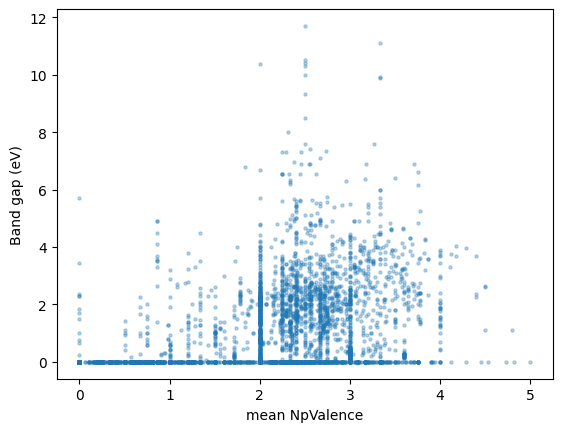

In [16]:
import matplotlib.pyplot as plt
plt.scatter(df["MagpieData mean NpValence"], y, s=5, alpha=0.3)
plt.xlabel("mean NpValence")
plt.ylabel("Band gap (eV)")
plt.show()

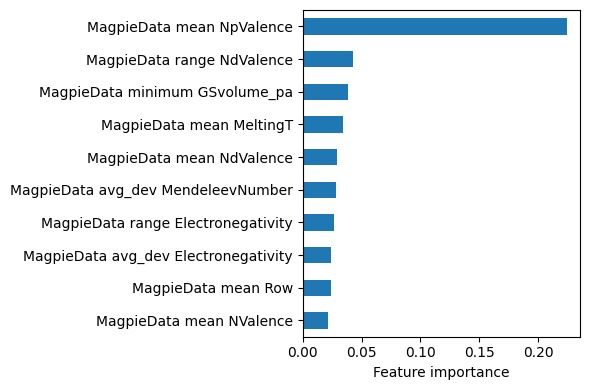

In [17]:
top10 = imp.sort_values(ascending=False).head(10)
top10.plot.barh(figsize=(6, 4)).invert_yaxis()
plt.xlabel("Feature importance")
plt.tight_layout()
plt.savefig("importance.png", dpi=200)
plt.show()